# Self-loop tests on small hand-built networks

Each cell calls `self_loop_utils.run_self_loop_test` on one of the test networks of `test_networks.py` (chain T1, ladder T2, five-node chain T7). The test solves the baseline network, adds one self-loop per entry of the node list, solves again, removes the loops and solves a third time; the asserts require the impedance to stay unchanged throughout. Each case is saved as an experiment with a before/after figure.

In [1]:
import sys, os, numpy as np, matplotlib.pyplot as plt

# ── Environment detection: Colab vs local ──────────────────────
in_colab = False
try:
    import google.colab
    in_colab = True
except ImportError:
    pass

if in_colab:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = '/content/drive/MyDrive/ColabProject/utils'
else:
    # Local: path relative to notebook directory (notebooks/test_self_loops.ipynb)
    utils_path = os.path.join(os.getcwd(), "..", "utils")

sys.path.insert(0, utils_path)

# ── Optional: ensure experiments directory exists ───────────────
exp_dir = os.path.join(os.path.dirname(utils_path), "experiments")
os.makedirs(exp_dir, exist_ok=True)

# ── Imports ─────────────────────────────────────────────────────
from test_networks import *
from self_loop_utils import *
from laplacian_utils import print_laplacian
from pipeline_utils import run_full_pipeline, run_impedance
from network_visualization import draw_chain_panel, draw_ladder_panel
from experiment_manager import setup_experiment
from impedance_calculator import ImpedanceCalculator, merge_boundary_nodes

print("All modules imported.")

# --- Helper: display inline + save to disk ---------------------
def display_and_save_plot(exp_dir, intersections, seg_baseline, seg_looped, seg_cleaned,
                           res_baseline, res_looped, res_cleaned, src_node, drn_node,
                           topology='chain', title=''):
    """
    Create a 3-panel voltage profile plot, display it inline (plt.show()),
    and save it to exp_dir/voltage_profiles.png.
    """
    from network_visualization import draw_chain_panel, draw_ladder_panel
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    cases = [
        (seg_baseline, res_baseline['voltages'], 'Baseline'),
        (seg_looped,   res_looped['voltages'],   'With loops'),
        (seg_cleaned,  res_cleaned['voltages'],  'After removal'),
    ]
    for ax, (seg, volts, label) in zip(axes, cases):
        if topology == 'ladder':
            draw_ladder_panel(ax, intersections, seg, volts, src_node, drn_node, label)
        else:
            draw_chain_panel(ax, intersections, seg, volts, src_node, drn_node, label)
    if title:
        fig.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()
    # Save to disk
    if exp_dir:
        path = os.path.join(exp_dir, 'voltage_profiles.png')
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print(f'    plot -> {path}')
    plt.close(fig)


All modules imported.


  [T1 baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1 looped]
    Nodes: 3,  Edges: 3  (self-loops: 1)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1 cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 645
  Timestamp: 20260615_203128
  Results directory: <project_root>/utils/../experiments/exp_645

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON saved

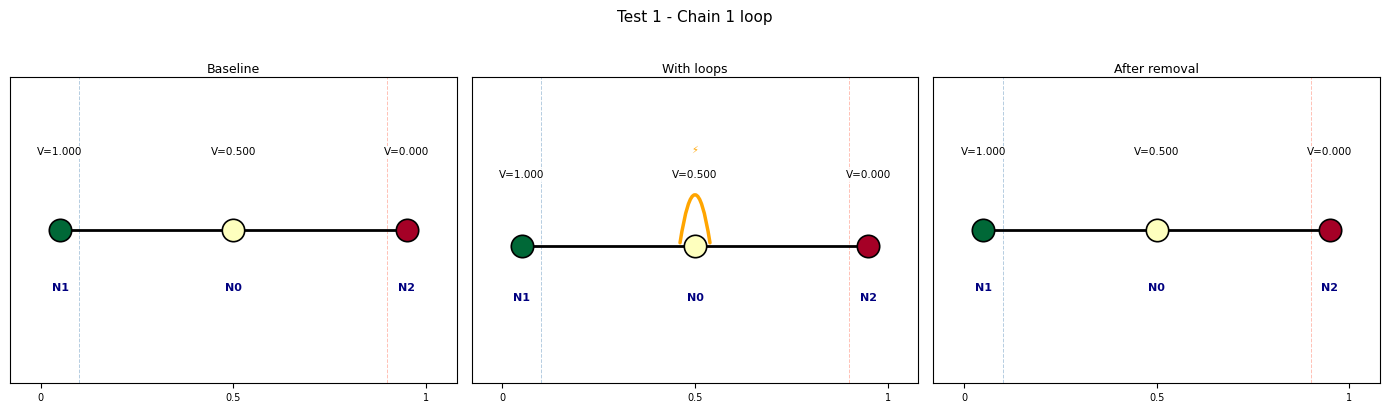

    plot -> <project_root>/utils/../experiments/exp_645/voltage_profiles.png


In [2]:
R_T1 = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [0], label='T1')
assert abs(R_T1["looped"]["impedance"] - R_T1["baseline"]["impedance"]) < 1e-3
assert abs(R_T1["cleaned"]["impedance"] - R_T1["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1 - Chain 1 loop',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1["looped"]["seg"], seg_cleaned=R_T1["cleaned"]["seg"],
    res_baseline=R_T1["baseline"]["result"], res_with_loops=R_T1["looped"]["result"], res_cleaned=R_T1["cleaned"]["result"],
    loop_description='1 loop internal', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1["looped"]["seg"], R_T1["cleaned"]["seg"],
    R_T1["baseline"]["result"], R_T1["looped"]["result"], R_T1["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1 - Chain 1 loop')

  [T2 baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2 looped]
    Nodes: 4,  Edges: 6  (self-loops: 1)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2 cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 646
  Timestamp: 20260615_203128
  Results directory: <project_root>/utils/../experiments/exp_646

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON saved

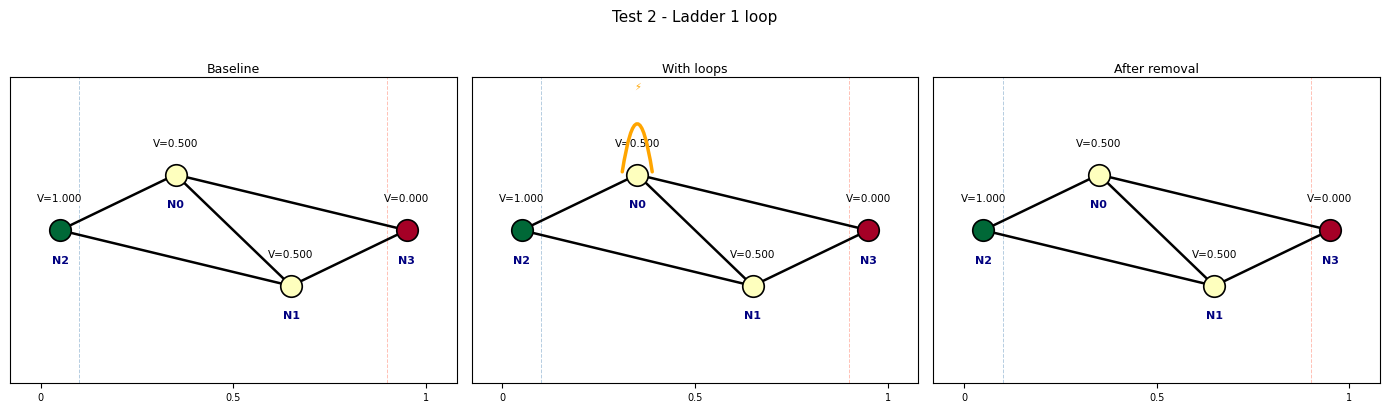

    plot -> <project_root>/utils/../experiments/exp_646/voltage_profiles.png


In [3]:
R_T2 = run_self_loop_test(intersections_t2,graph_t2,seg_t2,src_t2,drn_t2, k_test, [0], label='T2')
assert abs(R_T2["looped"]["impedance"] - R_T2["baseline"]["impedance"]) < 1e-3
assert abs(R_T2["cleaned"]["impedance"] - R_T2["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 2 - Ladder 1 loop',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T2["looped"]["seg"], seg_cleaned=R_T2["cleaned"]["seg"],
    res_baseline=R_T2["baseline"]["result"], res_with_loops=R_T2["looped"]["result"], res_cleaned=R_T2["cleaned"]["result"],
    loop_description='1 loop I1', src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T2["looped"]["seg"], R_T2["cleaned"]["seg"],
    R_T2["baseline"]["result"], R_T2["looped"]["result"], R_T2["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder', title='Test 2 - Ladder 1 loop')

  [T3 baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T3 looped]
    Nodes: 3,  Edges: 4  (self-loops: 2)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T3 cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 647
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_647

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON saved

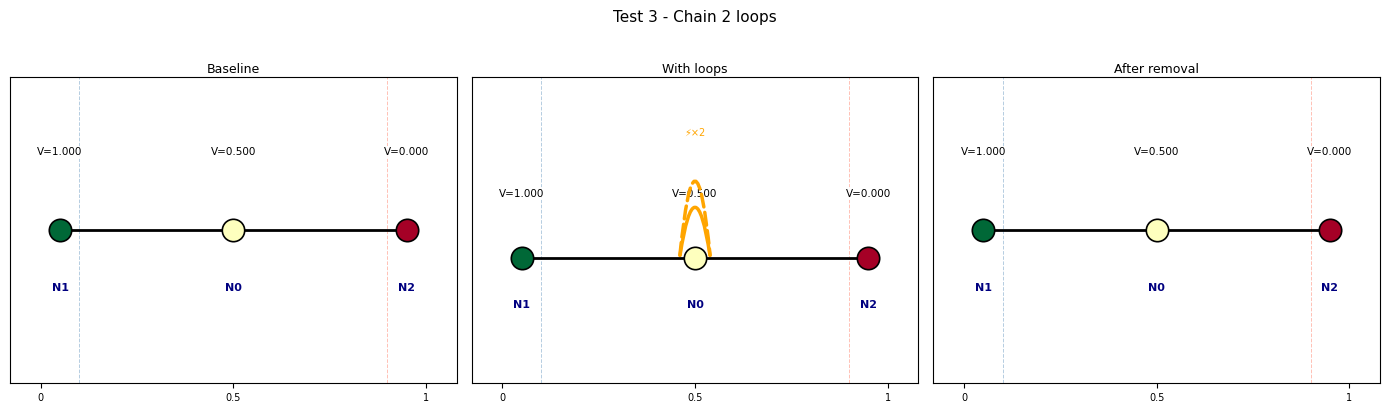

    plot -> <project_root>/utils/../experiments/exp_647/voltage_profiles.png


In [4]:
R_T3 = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [0, 0], label='T3')
assert abs(R_T3["looped"]["impedance"] - R_T3["baseline"]["impedance"]) < 1e-3
assert abs(R_T3["cleaned"]["impedance"] - R_T3["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 3 - Chain 2 loops',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T3["looped"]["seg"], seg_cleaned=R_T3["cleaned"]["seg"],
    res_baseline=R_T3["baseline"]["result"], res_with_loops=R_T3["looped"]["result"], res_cleaned=R_T3["cleaned"]["result"],
    loop_description='2 loops same node', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T3["looped"]["seg"], R_T3["cleaned"]["seg"],
    R_T3["baseline"]["result"], R_T3["looped"]["result"], R_T3["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 3 - Chain 2 loops')

  [T4 baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T4 looped]
    Nodes: 4,  Edges: 7  (self-loops: 2)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T4 cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 648
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_648

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON saved

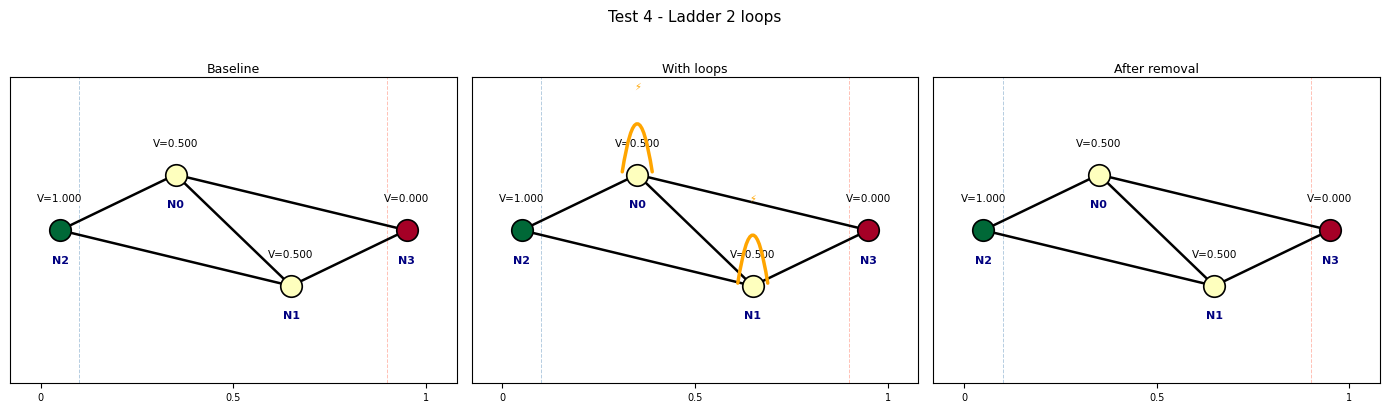

    plot -> <project_root>/utils/../experiments/exp_648/voltage_profiles.png


In [5]:
R_T4 = run_self_loop_test(intersections_t2,graph_t2,seg_t2,src_t2,drn_t2, k_test, [0, 1], label='T4')
assert abs(R_T4["looped"]["impedance"] - R_T4["baseline"]["impedance"]) < 1e-3
assert abs(R_T4["cleaned"]["impedance"] - R_T4["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 4 - Ladder 2 loops',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T4["looped"]["seg"], seg_cleaned=R_T4["cleaned"]["seg"],
    res_baseline=R_T4["baseline"]["result"], res_with_loops=R_T4["looped"]["result"], res_cleaned=R_T4["cleaned"]["result"],
    loop_description='loops I1+I2', src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T4["looped"]["seg"], R_T4["cleaned"]["seg"],
    R_T4["baseline"]["result"], R_T4["looped"]["result"], R_T4["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder', title='Test 4 - Ladder 2 loops')

  [T5 baseline]
    Nodes: 5,  Edges: 4  (self-loops: 0)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
  [T5 looped]
    Nodes: 5,  Edges: 7  (self-loops: 3)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
  [T5 cleaned]
    Nodes: 5,  Edges: 4  (self-loops: 0)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 649
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_649

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON saved

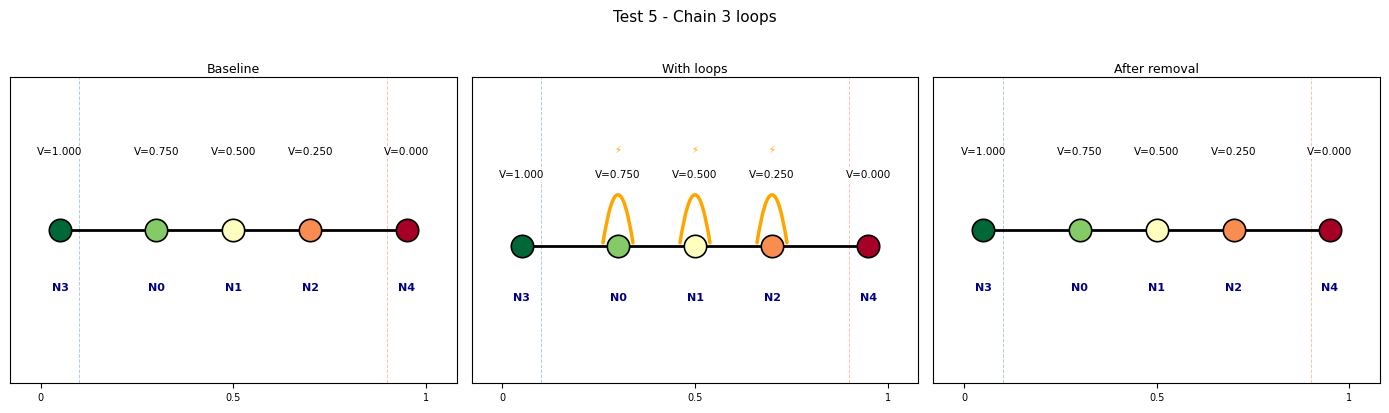

    plot -> <project_root>/utils/../experiments/exp_649/voltage_profiles.png


In [6]:
R_T5 = run_self_loop_test(intersections_t7,graph_t7,seg_t7,src_t7,drn_t7, k_test, [0, 1, 2], label='T5')
assert abs(R_T5["looped"]["impedance"] - R_T5["baseline"]["impedance"]) < 1e-3
assert abs(R_T5["cleaned"]["impedance"] - R_T5["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 5 - Chain 3 loops',
    intersections=intersections_t7, graph=graph_t7,
    seg_baseline=seg_t7, seg_with_loops=R_T5["looped"]["seg"], seg_cleaned=R_T5["cleaned"]["seg"],
    res_baseline=R_T5["baseline"]["result"], res_with_loops=R_T5["looped"]["result"], res_cleaned=R_T5["cleaned"]["result"],
    loop_description='loops I1+I2+I3', src_node=src_t7, drn_node=drn_t7)
display_and_save_plot(em.experiment_dir, intersections_t7,
    seg_t7, R_T5["looped"]["seg"], R_T5["cleaned"]["seg"],
    R_T5["baseline"]["result"], R_T5["looped"]["result"], R_T5["cleaned"]["result"],
    src_t7, drn_t7, topology='chain', title='Test 5 - Chain 3 loops')

  [T1a baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1a looped]
    Nodes: 3,  Edges: 3  (self-loops: 1)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1a cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 650
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_650

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

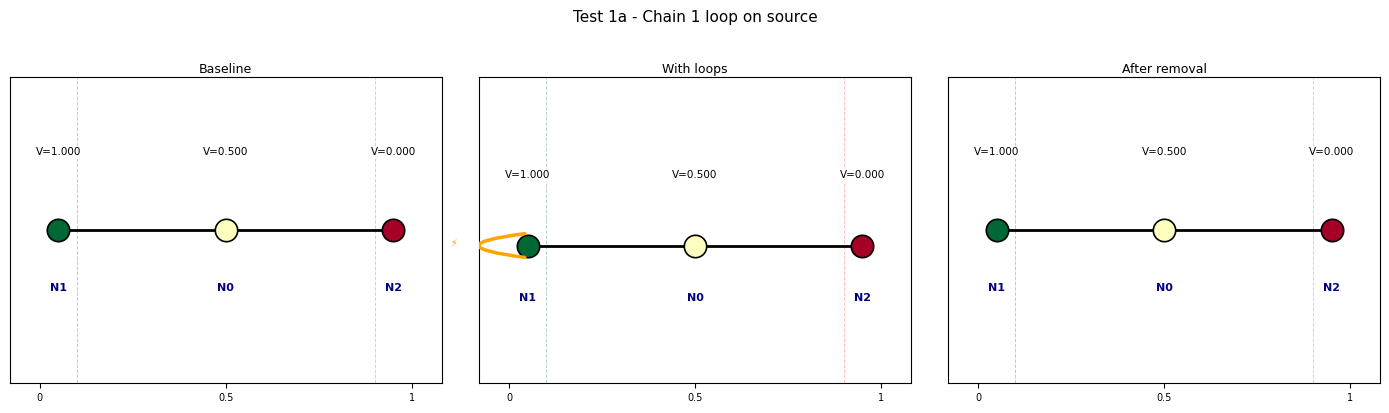

    plot -> <project_root>/utils/../experiments/exp_650/voltage_profiles.png


In [7]:
R_T1a = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [1], label='T1a')
assert abs(R_T1a["looped"]["impedance"] - R_T1a["baseline"]["impedance"]) < 1e-3
assert abs(R_T1a["cleaned"]["impedance"] - R_T1a["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1a - Chain 1 loop on source',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1a["looped"]["seg"], seg_cleaned=R_T1a["cleaned"]["seg"],
    res_baseline=R_T1a["baseline"]["result"], res_with_loops=R_T1a["looped"]["result"], res_cleaned=R_T1a["cleaned"]["result"],
    loop_description='1 loop on source node', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1a["looped"]["seg"], R_T1a["cleaned"]["seg"],
    R_T1a["baseline"]["result"], R_T1a["looped"]["result"], R_T1a["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1a - Chain 1 loop on source')

  [T1b baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1b looped]
    Nodes: 3,  Edges: 3  (self-loops: 1)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1b cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 651
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_651

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

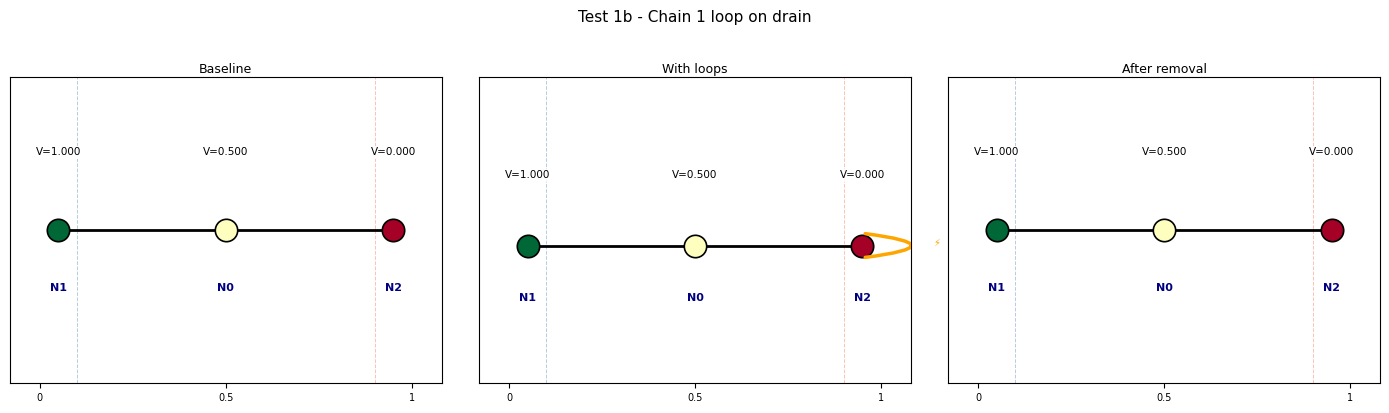

    plot -> <project_root>/utils/../experiments/exp_651/voltage_profiles.png


In [8]:
R_T1b = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [2], label='T1b')
assert abs(R_T1b["looped"]["impedance"] - R_T1b["baseline"]["impedance"]) < 1e-3
assert abs(R_T1b["cleaned"]["impedance"] - R_T1b["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1b - Chain 1 loop on drain',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1b["looped"]["seg"], seg_cleaned=R_T1b["cleaned"]["seg"],
    res_baseline=R_T1b["baseline"]["result"], res_with_loops=R_T1b["looped"]["result"], res_cleaned=R_T1b["cleaned"]["result"],
    loop_description='1 loop on drain node', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1b["looped"]["seg"], R_T1b["cleaned"]["seg"],
    R_T1b["baseline"]["result"], R_T1b["looped"]["result"], R_T1b["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1b - Chain 1 loop on drain')

  [T1c baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1c looped]
    Nodes: 3,  Edges: 3  (self-loops: 1)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1c cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 652
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_652

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

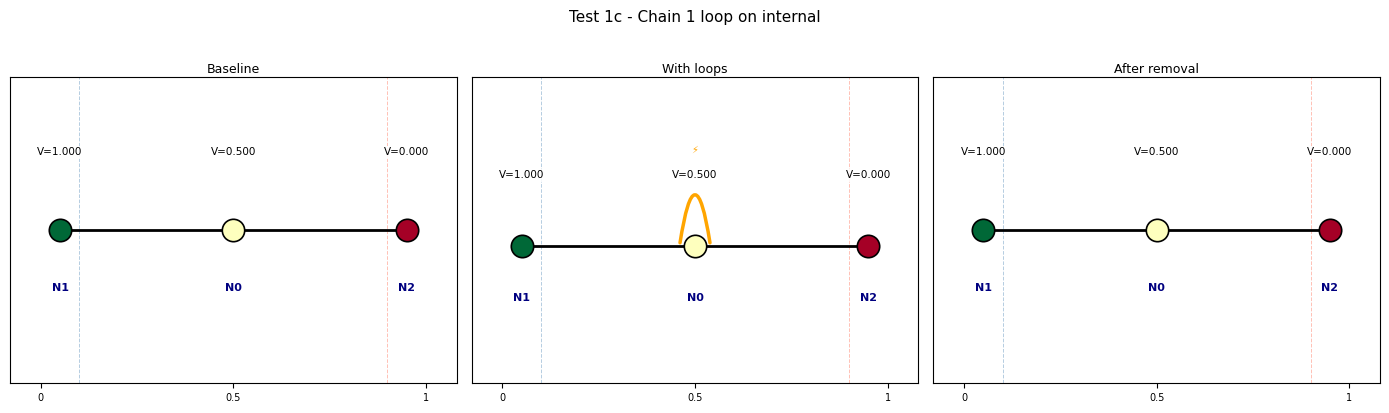

    plot -> <project_root>/utils/../experiments/exp_652/voltage_profiles.png


In [9]:
R_T1c = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [0], label='T1c')
assert abs(R_T1c["looped"]["impedance"] - R_T1c["baseline"]["impedance"]) < 1e-3
assert abs(R_T1c["cleaned"]["impedance"] - R_T1c["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1c - Chain 1 loop on internal',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1c["looped"]["seg"], seg_cleaned=R_T1c["cleaned"]["seg"],
    res_baseline=R_T1c["baseline"]["result"], res_with_loops=R_T1c["looped"]["result"], res_cleaned=R_T1c["cleaned"]["result"],
    loop_description='1 loop on internal node', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1c["looped"]["seg"], R_T1c["cleaned"]["seg"],
    R_T1c["baseline"]["result"], R_T1c["looped"]["result"], R_T1c["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1c - Chain 1 loop on internal')

  [T1d baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1d looped]
    Nodes: 3,  Edges: 5  (self-loops: 3)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1d cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 653
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_653

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

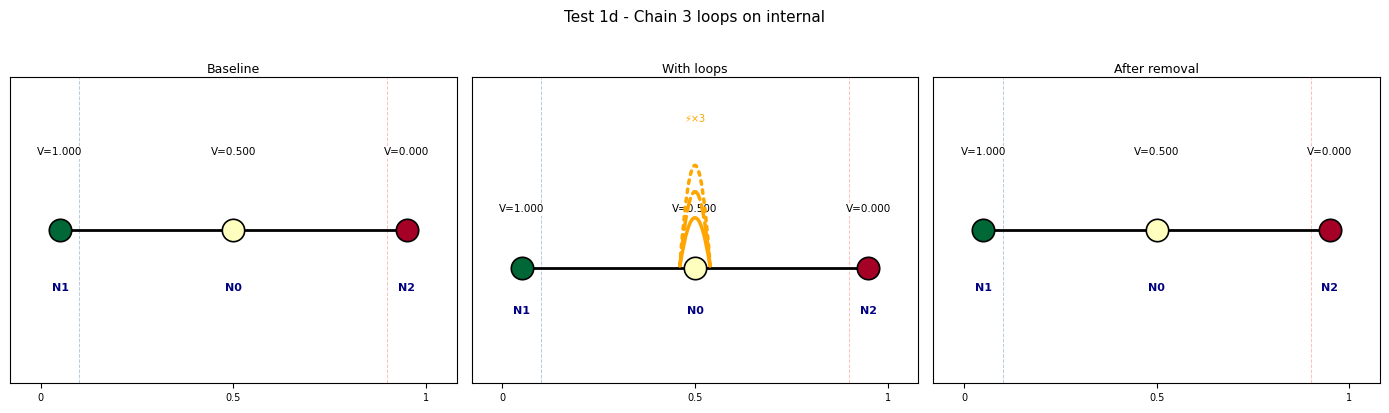

    plot -> <project_root>/utils/../experiments/exp_653/voltage_profiles.png


In [10]:
R_T1d = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [0, 0, 0], label='T1d')
assert abs(R_T1d["looped"]["impedance"] - R_T1d["baseline"]["impedance"]) < 1e-3
assert abs(R_T1d["cleaned"]["impedance"] - R_T1d["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T1d["looped"]["seg"], src_t1, drn_t1) == True
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1d - Chain 3 loops on internal',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1d["looped"]["seg"], seg_cleaned=R_T1d["cleaned"]["seg"],
    res_baseline=R_T1d["baseline"]["result"], res_with_loops=R_T1d["looped"]["result"], res_cleaned=R_T1d["cleaned"]["result"],
    loop_description='3 loops on internal node', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1d["looped"]["seg"], R_T1d["cleaned"]["seg"],
    R_T1d["baseline"]["result"], R_T1d["looped"]["result"], R_T1d["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1d - Chain 3 loops on internal')

  [T1e baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1e looped]
    Nodes: 3,  Edges: 6  (self-loops: 4)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1e cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 654
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_654

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

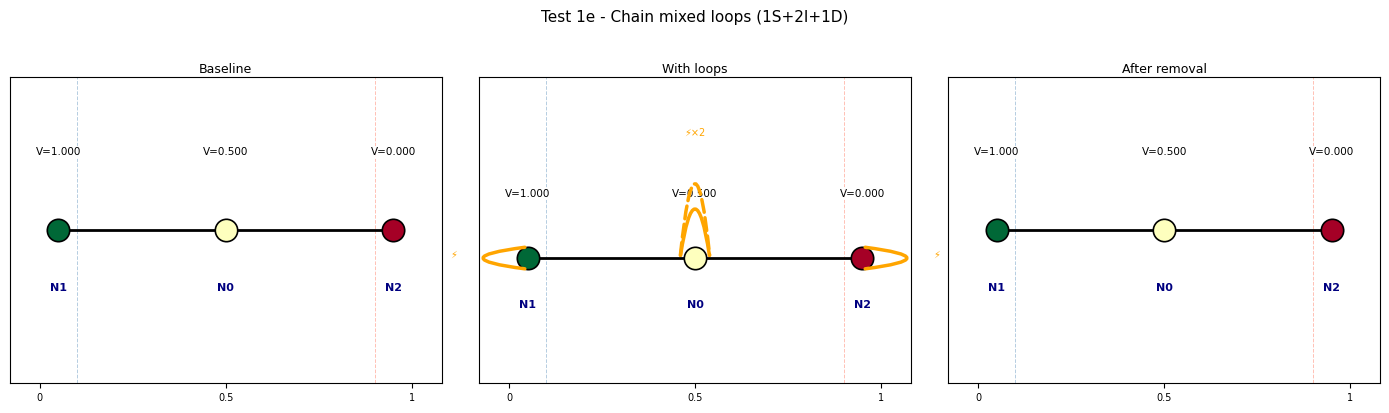

    plot -> <project_root>/utils/../experiments/exp_654/voltage_profiles.png


In [11]:
R_T1e = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [1, 0, 0, 2], label='T1e')
assert abs(R_T1e["looped"]["impedance"] - R_T1e["baseline"]["impedance"]) < 1e-3
assert abs(R_T1e["cleaned"]["impedance"] - R_T1e["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T1e["looped"]["seg"], src_t1, drn_t1) == True
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1e - Chain mixed loops (1S+2I+1D)',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1e["looped"]["seg"], seg_cleaned=R_T1e["cleaned"]["seg"],
    res_baseline=R_T1e["baseline"]["result"], res_with_loops=R_T1e["looped"]["result"], res_cleaned=R_T1e["cleaned"]["result"],
    loop_description='1 loop source + 2 loops internal + 1 loop drain', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1e["looped"]["seg"], R_T1e["cleaned"]["seg"],
    R_T1e["baseline"]["result"], R_T1e["looped"]["result"], R_T1e["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1e - Chain mixed loops (1S+2I+1D)')

  [T1f baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1f looped]
    Nodes: 3,  Edges: 7  (self-loops: 5)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1f cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 655
  Timestamp: 20260615_203129
  Results directory: <project_root>/utils/../experiments/exp_655

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

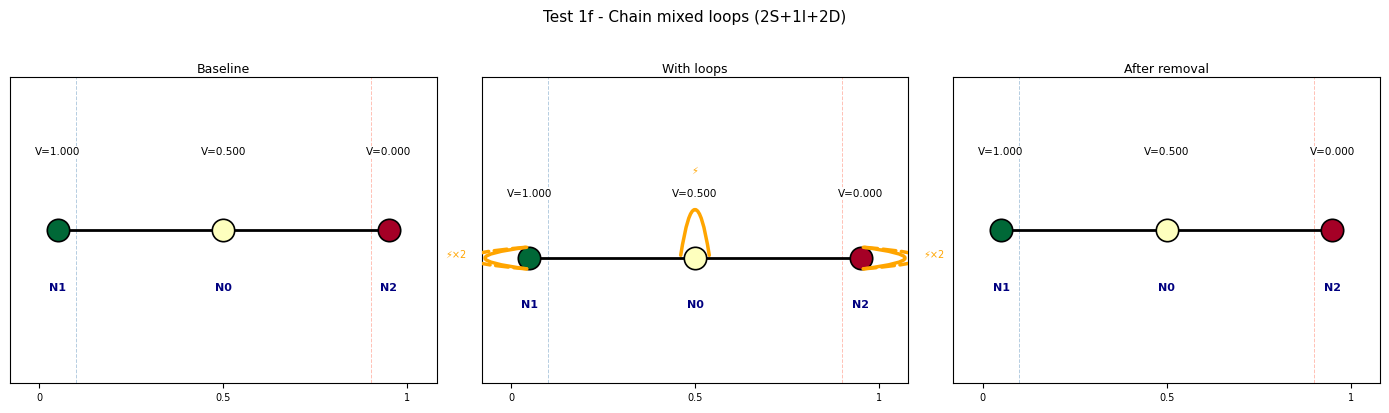

    plot -> <project_root>/utils/../experiments/exp_655/voltage_profiles.png


In [12]:
R_T1f = run_self_loop_test(intersections_t1,graph_t1,seg_t1,src_t1,drn_t1, k_test, [1, 1, 0, 2, 2], label='T1f')
assert abs(R_T1f["looped"]["impedance"] - R_T1f["baseline"]["impedance"]) < 1e-3
assert abs(R_T1f["cleaned"]["impedance"] - R_T1f["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T1f["looped"]["seg"], src_t1, drn_t1) == True
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 1f - Chain mixed loops (2S+1I+2D)',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1f["looped"]["seg"], seg_cleaned=R_T1f["cleaned"]["seg"],
    res_baseline=R_T1f["baseline"]["result"], res_with_loops=R_T1f["looped"]["result"], res_cleaned=R_T1f["cleaned"]["result"],
    loop_description='2 loops source + 1 loop internal + 2 loops drain', src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1f["looped"]["seg"], R_T1f["cleaned"]["seg"],
    R_T1f["baseline"]["result"], R_T1f["looped"]["result"], R_T1f["cleaned"]["result"],
    src_t1, drn_t1, topology='chain', title='Test 1f - Chain mixed loops (2S+1I+2D)')

  [T2b baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2b looped]
    Nodes: 4,  Edges: 7  (self-loops: 2)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2b cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 656
  Timestamp: 20260615_203130
  Results directory: <project_root>/utils/../experiments/exp_656

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

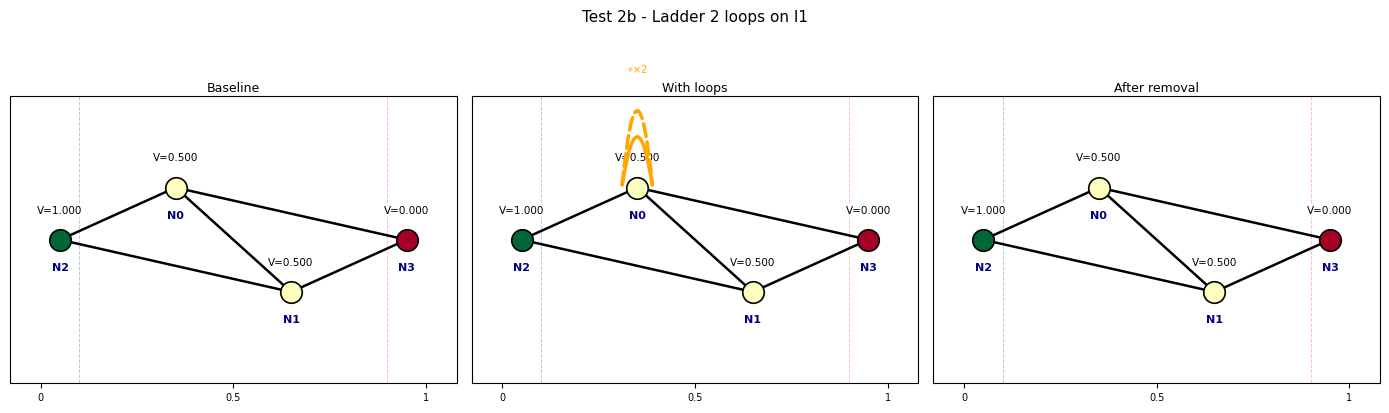

    plot -> <project_root>/utils/../experiments/exp_656/voltage_profiles.png


In [13]:
R_T2b = run_self_loop_test(intersections_t2,graph_t2,seg_t2,src_t2,drn_t2, k_test, [0, 0], label='T2b')
assert abs(R_T2b["looped"]["impedance"] - R_T2b["baseline"]["impedance"]) < 1e-3
assert abs(R_T2b["cleaned"]["impedance"] - R_T2b["baseline"]["impedance"]) < 1e-6
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 2b - Ladder 2 loops on I1',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T2b["looped"]["seg"], seg_cleaned=R_T2b["cleaned"]["seg"],
    res_baseline=R_T2b["baseline"]["result"], res_with_loops=R_T2b["looped"]["result"], res_cleaned=R_T2b["cleaned"]["result"],
    loop_description='2 loops on I1', src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T2b["looped"]["seg"], R_T2b["cleaned"]["seg"],
    R_T2b["baseline"]["result"], R_T2b["looped"]["result"], R_T2b["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder', title='Test 2b - Ladder 2 loops on I1')

  [T2c baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2c looped]
    Nodes: 4,  Edges: 9  (self-loops: 4)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T2c cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 657
  Timestamp: 20260615_203130
  Results directory: <project_root>/utils/../experiments/exp_657

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'
  [OK] JSON sa

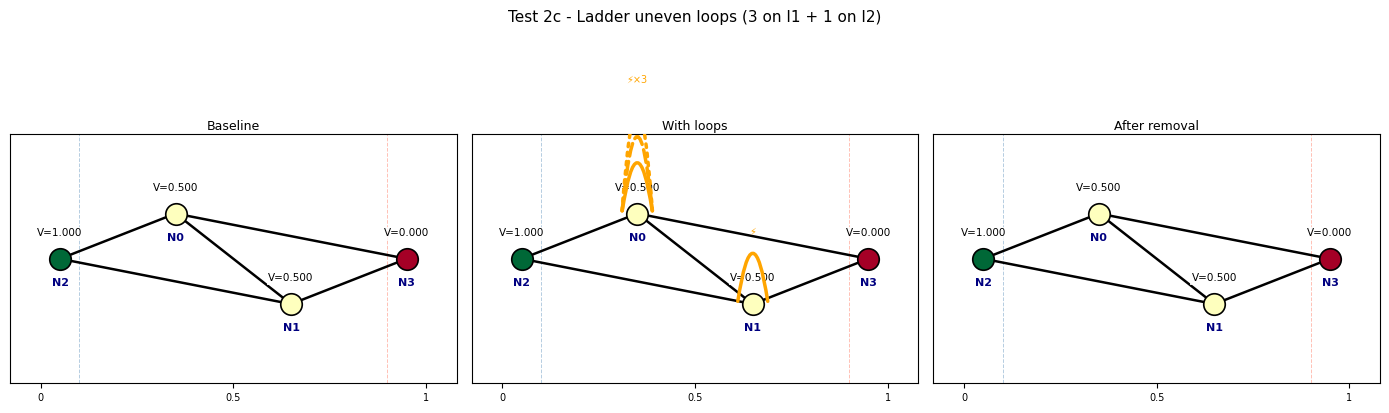

    plot -> <project_root>/utils/../experiments/exp_657/voltage_profiles.png


In [14]:
R_T2c = run_self_loop_test(intersections_t2,graph_t2,seg_t2,src_t2,drn_t2, k_test, [0, 0, 0, 1], label='T2c')
assert abs(R_T2c["looped"]["impedance"] - R_T2c["baseline"]["impedance"]) < 1e-3
assert abs(R_T2c["cleaned"]["impedance"] - R_T2c["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T2c["looped"]["seg"], src_t2, drn_t2) == True
em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test, title='Test 2c - Ladder uneven loops (3 on I1 + 1 on I2)',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T2c["looped"]["seg"], seg_cleaned=R_T2c["cleaned"]["seg"],
    res_baseline=R_T2c["baseline"]["result"], res_with_loops=R_T2c["looped"]["result"], res_cleaned=R_T2c["cleaned"]["result"],
    loop_description='3 loops on I1 + 1 loop on I2', src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T2c["looped"]["seg"], R_T2c["cleaned"]["seg"],
    R_T2c["baseline"]["result"], R_T2c["looped"]["result"], R_T2c["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder', title='Test 2c - Ladder uneven loops (3 on I1 + 1 on I2)')